In [36]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

from tensorflow import keras
from keras.layers import Dense, Input, Embedding, GlobalMaxPooling1D, Conv1D , MaxPooling1D
from keras.models import Model, Sequential
from keras.losses import SparseCategoricalCrossentropy

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

import warnings
warnings.filterwarnings('ignore')

## Text Classification using CNN

In [2]:
df = pd.read_csv('BBC_Text_CLS.csv')
df.head()

,text,labels
0,Ad sales boost Time Warner profit\n\nQuarterly...,business
1,Dollar gains on Greenspan speech\n\nThe dollar...,business
2,Yukos unit buyer faces loan claim\n\nThe owner...,business
3,High fuel prices hit BA's profits\n\nBritish A...,business
4,Pernod takeover talk lifts Domecq\n\nShares in...,business


In [6]:
df['labels'].value_counts()

labels
sport            511
business         510
politics         417
tech             401
entertainment    386
Name: count, dtype: int64

In [4]:
df['targets'] = df['labels'].astype('category').cat.codes

In [ ]:
# Number of classes
K = df['targets'].max() + 1
K

np.int8(5)

In [8]:
df.sample(5)

,text,labels,targets
1029,Ban on hunting comes into force\n\nFox hunting...,politics,2
102,"US insurer Marsh cuts 2,500 jobs\n\nUp to 2,50...",business,0
814,"The comic book genius of Stan Lee\n\nStan Lee,...",entertainment,1
1167,Kennedy looks to election gains\n\nThey may no...,politics,2
1863,Apple iPod family expands market\n\nApple has ...,tech,4


## Dataset Split

In [9]:
df_train, df_test = train_test_split(df, test_size=0.3, random_state=42)

In [ ]:
# Convert sentences to sequences 

MAX_VOCAB_SIZE = 2000

tokenizer = Tokenizer(num_words=MAX_VOCAB_SIZE)

tokenizer.fit_on_texts(df['text'])  # Integer mapping of each token

In [12]:
sequences_train = tokenizer.texts_to_sequences(df_train['text'])  # Integer Sequence Conversion

sequences_test = tokenizer.texts_to_sequences(df_test['text'])  

In [13]:
word2idx = tokenizer.word_index  

V = len(word2idx)  # Vocabulary Size

print("Found %s unique tokens." % V)

Found 32359 unique tokens.


In [ ]:
# Padding

data_train = pad_sequences(sequences_train)
data_train.shape

(1557, 2831)

In [15]:
T = data_train.shape[1]  

data_test = pad_sequences(sequences_test, maxlen=T)
data_test.shape

(668, 2831)

In [17]:
D = 50  # Embedding Size

## Model Building

In [ ]:
model = Sequential([Input(shape=(T,)),

                    Embedding(input_dim=V+1, output_dim=D, input_length=T),

                    Conv1D(filters=32, kernel_size=3, activation='relu'),

                    GlobalMaxPooling1D(),
                    Dense(units=K, activation='softmax')
                    ])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 2831, 50)       │     1,618,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 2829, 32)       │         4,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_1          │ (None, 32)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,622,997 (6.19 MB)

 Trainable params: 1,622,997 (6.19 MB)

 Non-trainable params: 0 (0.00 B)

In [20]:
model.compile(loss=SparseCategoricalCrossentropy(), 
              optimizer='adam', metrics=['accuracy'])

In [23]:
history = model.fit(
                    data_train, 
                    df_train['targets'],                    
                    validation_data=(data_test, df_test['targets']),
                    epochs=10, 
                    batch_size=32
                )

Epoch 1/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 64ms/step - accuracy: 0.2640 - loss: 1.5584 - val_accuracy: 0.3847 - val_loss: 1.4769
Epoch 2/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 3s 61ms/step - accuracy: 0.6410 - loss: 1.2772 - val_accuracy: 0.7710 - val_loss: 1.0646
Epoch 3/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - accuracy: 0.8581 - loss: 0.7733 - val_accuracy: 0.8623 - val_loss: 0.5972
Epoch 4/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 3s 64ms/step - accuracy: 0.9171 - loss: 0.4158 - val_accuracy: 0.9042 - val_loss: 0.3963
Epoch 5/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 73ms/step - accuracy: 0.9473 - loss: 0.2599 - val_accuracy: 0.9132 - val_loss: 0.3067
Epoch 6/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 77ms/step - accuracy: 0.9672 - loss: 0.1775 - val_accuracy: 0.9222 - val_loss: 0.2628
Epoch 7/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 3s 68ms/step - accuracy: 0.9814 - loss: 0.1270 - val_accuracy: 0.9341 - val_loss: 0.2374
Epoch 8/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 3s 68ms/step - accuracy: 0.9897 - loss: 0.0936 - val_accuracy: 0.9326 - v

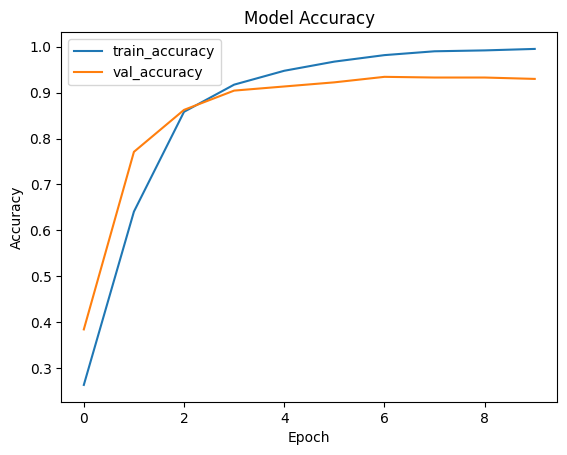

In [27]:
plt.plot(history.history['accuracy'], label='train_accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

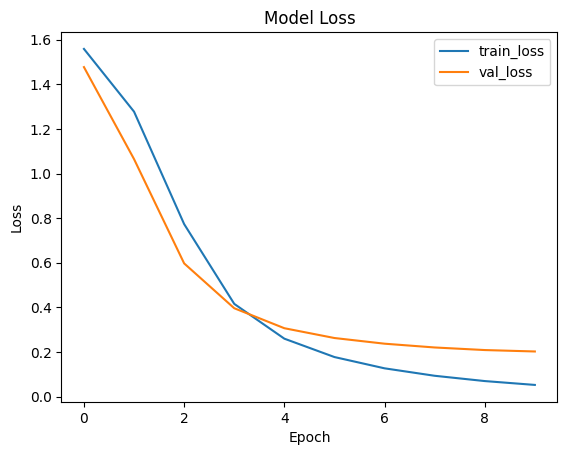

In [28]:
plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_loss'], label = 'val_loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [32]:
y_pred = model.predict(data_test).argmax(axis=1)

21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


In [33]:
print(classification_report(df_test['targets'], y_pred))

              precision    recall  f1-score   support

           0       0.87      0.93      0.90       165
           1       0.98      0.88      0.93       118
           2       0.89      0.92      0.91       120
           3       0.98      0.99      0.99       140
           4       0.95      0.92      0.93       125

    accuracy                           0.93       668
   macro avg       0.93      0.93      0.93       668
weighted avg       0.93      0.93      0.93       668



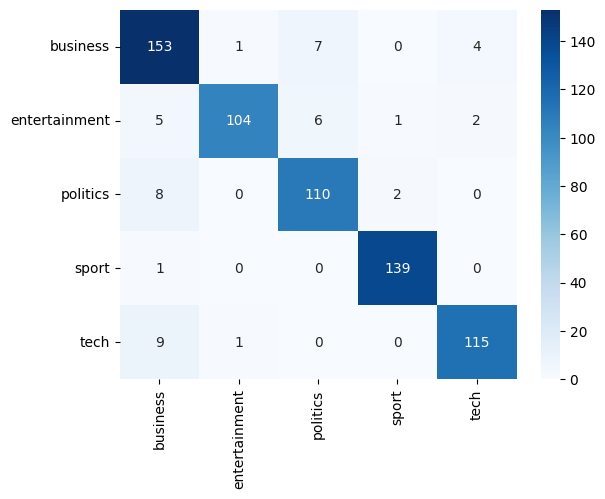

In [38]:
cm = confusion_matrix(df_test['targets'], y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=df['labels'].unique(), yticklabels=df['labels'].unique())
plt.show()